In [1]:
# ==========================================
# CAMPUSOPTI AI - ENVIRONMENT VERIFICATION
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import ortools

print("CampusOpti AI Environment Setup Successful!")

print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Scikit-learn Version:", sklearn.__version__)
print("OR-Tools Version:", ortools.__version__)

Matplotlib is building the font cache; this may take a moment.


CampusOpti AI Environment Setup Successful!
Pandas Version: 3.1.1
NumPy Version: 2.4.6
Scikit-learn Version: 1.9.1
OR-Tools Version: 9.15.6755


In [2]:

# =====================================================
# CAMPUSOPTI AI - SYNTHETIC DATASET GENERATION
# =====================================================

import pandas as pd
import numpy as np
import os

# Set random seed for reproducibility
np.random.seed(42)

# Create dataset folder
os.makedirs("../dataset", exist_ok=True)

# =====================================================
# 1. FACULTY DATASET
# =====================================================

faculty = pd.DataFrame({
    "faculty_id": [f"F{i:03}" for i in range(1, 21)],
    "faculty_name": [f"Faculty_{i}" for i in range(1, 21)],
    "department": np.random.choice(
        ["AIDS", "Computer", "IT", "ENTC"], 20
    ),
    "max_lectures_per_day": np.random.randint(3, 6, 20)
})

# =====================================================
# 2. CLASSROOM DATASET
# =====================================================

classrooms = pd.DataFrame({
    "room_id": [f"R{i:03}" for i in range(1, 15)],
    "room_type": ["Classroom"] * 10 + ["Lab"] * 4,
    "capacity": np.random.randint(40, 81, 14)
})

# =====================================================
# 3. STUDENT BATCH DATASET
# =====================================================

batches = pd.DataFrame({
    "batch_id": [f"B{i:03}" for i in range(1, 9)],
    "department": ["AIDS"] * 8,
    "semester": [3, 3, 4, 4, 5, 5, 6, 6],
    "student_count": np.random.randint(40, 71, 8)
})

# =====================================================
# 4. SUBJECT DATASET
# =====================================================

subjects = pd.DataFrame({
    "subject_id": [f"S{i:03}" for i in range(1, 16)],
    "subject_name": [
        "Python", "Machine Learning", "DBMS",
        "Data Structures", "Mathematics",
        "Artificial Intelligence", "Computer Networks",
        "Operating Systems", "Statistics", "Web Technology",
        "Deep Learning", "Software Engineering",
        "Cloud Computing", "Data Mining", "Cyber Security"
    ],
    "required_lectures_per_week": np.random.randint(2, 5, 15),
    "required_room_type": [
        "Lab", "Lab", "Classroom", "Classroom",
        "Classroom", "Classroom", "Classroom",
        "Classroom", "Classroom", "Lab",
        "Lab", "Classroom", "Lab", "Classroom",
        "Classroom"
    ]
})

# =====================================================
# 5. TIME SLOTS DATASET
# =====================================================

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

times = [
    "09:00-10:00",
    "10:00-11:00",
    "11:15-12:15",
    "12:15-13:15",
    "14:00-15:00",
    "15:00-16:00"
]

time_slots = pd.DataFrame([
    {
        "slot_id": f"T{i+1:02}",
        "day": day,
        "time": time
    }
    for i, (day, time) in enumerate(
        [(d, t) for d in days for t in times]
    )
])

# =====================================================
# 6. SAVE DATASETS
# =====================================================

faculty.to_csv("../dataset/faculty.csv", index=False)
classrooms.to_csv("../dataset/classrooms.csv", index=False)
batches.to_csv("../dataset/student_batches.csv", index=False)
subjects.to_csv("../dataset/subjects.csv", index=False)
time_slots.to_csv("../dataset/time_slots.csv", index=False)

print("All datasets generated successfully!")

print("\nDataset Shapes:")
print("Faculty:", faculty.shape)
print("Classrooms:", classrooms.shape)
print("Batches:", batches.shape)
print("Subjects:", subjects.shape)
print("Time Slots:", time_slots.shape)


All datasets generated successfully!

Dataset Shapes:
Faculty: (20, 4)
Classrooms: (14, 3)
Batches: (8, 4)
Subjects: (15, 4)
Time Slots: (30, 3)


In [4]:
display(faculty.head())
display(classrooms.head())
display(batches.head())
display(subjects.head())
display(time_slots.head())

,faculty_id,faculty_name,department,max_lectures_per_day
0,F001,Faculty_1,IT,4
1,F002,Faculty_2,ENTC,3
2,F003,Faculty_3,AIDS,4
3,F004,Faculty_4,IT,4
4,F005,Faculty_5,IT,4


,room_id,room_type,capacity
0,R001,Classroom,42
1,R002,Classroom,76
2,R003,Classroom,46
3,R004,Classroom,60
4,R005,Classroom,48


,batch_id,department,semester,student_count
0,B001,AIDS,3,67
1,B002,AIDS,3,54
2,B003,AIDS,4,67
3,B004,AIDS,4,46
4,B005,AIDS,5,51


,subject_id,subject_name,required_lectures_per_week,required_room_type
0,S001,Python,4,Lab
1,S002,Machine Learning,3,Lab
2,S003,DBMS,2,Classroom
3,S004,Data Structures,3,Classroom
4,S005,Mathematics,3,Classroom


,slot_id,day,time
0,T01,Monday,09:00-10:00
1,T02,Monday,10:00-11:00
2,T03,Monday,11:15-12:15
3,T04,Monday,12:15-13:15
4,T05,Monday,14:00-15:00


In [5]:

# =====================================================
# 7. FACULTY-SUBJECT MAPPING
# =====================================================

faculty_subjects = pd.DataFrame({
    "subject_id": subjects["subject_id"],
    "faculty_id": [
        faculty["faculty_id"].iloc[i % len(faculty)]
        for i in range(len(subjects))
    ]
})

faculty_subjects.to_csv(
    "../dataset/faculty_subjects.csv", index=False
)

display(faculty_subjects.head(10))

print("Faculty-Subject mapping created!")



,subject_id,faculty_id
0,S001,F001
1,S002,F002
2,S003,F003
3,S004,F004
4,S005,F005
5,S006,F006
6,S007,F007
7,S008,F008
8,S009,F009
9,S010,F010


Faculty-Subject mapping created!


In [6]:

# =====================================================
# 8. BATCH-SUBJECT REQUIREMENTS
# =====================================================

batch_subjects_list = []

for _, batch in batches.iterrows():

    selected_subjects = subjects.sample(
        n=6,
        random_state=42 + int(batch["batch_id"][-3:])
    )

    for _, subject in selected_subjects.iterrows():

        faculty_id = faculty_subjects.loc[
            faculty_subjects["subject_id"] == subject["subject_id"],
            "faculty_id"
        ].iloc[0]

        batch_subjects_list.append({
            "batch_id": batch["batch_id"],
            "subject_id": subject["subject_id"],
            "faculty_id": faculty_id,
            "lectures_per_week": subject["required_lectures_per_week"],
            "required_room_type": subject["required_room_type"]
        })

batch_subjects = pd.DataFrame(batch_subjects_list)

batch_subjects.to_csv(
    "../dataset/batch_subjects.csv", index=False
)

display(batch_subjects.head(10))

print("Batch-Subject requirements created!")


,batch_id,subject_id,faculty_id,lectures_per_week,required_room_type
0,B001,S010,F010,3,Lab
1,B001,S008,F008,3,Classroom
2,B001,S012,F012,4,Classroom
3,B001,S015,F015,3,Classroom
4,B001,S003,F003,2,Classroom
5,B001,S007,F007,3,Classroom
6,B002,S006,F006,3,Classroom
7,B002,S009,F009,3,Classroom
8,B002,S007,F007,3,Classroom
9,B002,S008,F008,3,Classroom


Batch-Subject requirements created!


In [7]:

# =====================================================
# 9. FACULTY AVAILABILITY
# =====================================================

availability_records = []

for _, member in faculty.iterrows():

    for _, slot in time_slots.iterrows():

        availability_records.append({
            "faculty_id": member["faculty_id"],
            "slot_id": slot["slot_id"],
            "available": np.random.choice(
                [1, 0],
                p=[0.85, 0.15]
            )
        })

faculty_availability = pd.DataFrame(availability_records)

faculty_availability.to_csv(
    "../dataset/faculty_availability.csv", index=False
)

display(faculty_availability.head(10))

print("Faculty availability created!")


,faculty_id,slot_id,available
0,F001,T01,1
1,F001,T02,0
2,F001,T03,1
3,F001,T04,1
4,F001,T05,1
5,F001,T06,1
6,F001,T07,0
7,F001,T08,1
8,F001,T09,1
9,F001,T10,1


Faculty availability created!


In [8]:
import os

print("CAMPUSOPTI AI - DATASET SUMMARY")
print("=" * 45)

for file in sorted(os.listdir("../dataset")):

    if file.endswith(".csv"):

        df = pd.read_csv("../dataset/" + file)

        print(f"{file:30} {df.shape}")

CAMPUSOPTI AI - DATASET SUMMARY
batch_subjects.csv             (48, 5)
classrooms.csv                 (14, 3)
faculty.csv                    (20, 4)
faculty_availability.csv       (600, 3)
faculty_subjects.csv           (15, 2)
student_batches.csv            (8, 4)
subjects.csv                   (15, 4)
time_slots.csv                 (30, 3)


In [9]:

# =====================================================
# CAMPUSOPTI AI - LOADING ALL DATASETS
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

faculty = pd.read_csv("../dataset/faculty.csv")
classrooms = pd.read_csv("../dataset/classrooms.csv")
batches = pd.read_csv("../dataset/student_batches.csv")
subjects = pd.read_csv("../dataset/subjects.csv")
time_slots = pd.read_csv("../dataset/time_slots.csv")

faculty_subjects = pd.read_csv("../dataset/faculty_subjects.csv")
batch_subjects = pd.read_csv("../dataset/batch_subjects.csv")
faculty_availability = pd.read_csv("../dataset/faculty_availability.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [10]:

# =====================================================
# DATASET INFORMATION
# =====================================================

datasets = {
    "Faculty": faculty,
    "Classrooms": classrooms,
    "Batches": batches,
    "Subjects": subjects,
    "Time Slots": time_slots,
    "Faculty Subjects": faculty_subjects,
    "Batch Subjects": batch_subjects,
    "Faculty Availability": faculty_availability
}

for name, df in datasets.items():

    print("\n", "=" * 50)
    print("Dataset:", name)

    print("Shape:", df.shape)

    print("\nColumn Information:")
    print(df.dtypes)

    print("\nFirst Five Records:")
    display(df.head())



Dataset: Faculty
Shape: (20, 4)

Column Information:
faculty_id                str
faculty_name              str
department                str
max_lectures_per_day    int64
dtype: object

First Five Records:


,faculty_id,faculty_name,department,max_lectures_per_day
0,F001,Faculty_1,IT,4
1,F002,Faculty_2,ENTC,3
2,F003,Faculty_3,AIDS,4
3,F004,Faculty_4,IT,4
4,F005,Faculty_5,IT,4



Dataset: Classrooms
Shape: (14, 3)

Column Information:
room_id        str
room_type      str
capacity     int64
dtype: object

First Five Records:


,room_id,room_type,capacity
0,R001,Classroom,42
1,R002,Classroom,76
2,R003,Classroom,46
3,R004,Classroom,60
4,R005,Classroom,48



Dataset: Batches
Shape: (8, 4)

Column Information:
batch_id           str
department         str
semester         int64
student_count    int64
dtype: object

First Five Records:


,batch_id,department,semester,student_count
0,B001,AIDS,3,67
1,B002,AIDS,3,54
2,B003,AIDS,4,67
3,B004,AIDS,4,46
4,B005,AIDS,5,51


... (6 outputs left out)


Dataset: Batch Subjects
Shape: (48, 5)

Column Information:
batch_id                str
subject_id              str
faculty_id              str
lectures_per_week     int64
required_room_type      str
dtype: object

First Five Records:


,batch_id,subject_id,faculty_id,lectures_per_week,required_room_type
0,B001,S010,F010,3,Lab
1,B001,S008,F008,3,Classroom
2,B001,S012,F012,4,Classroom
3,B001,S015,F015,3,Classroom
4,B001,S003,F003,2,Classroom



Dataset: Faculty Availability
Shape: (600, 3)

Column Information:
faculty_id      str
slot_id         str
available     int64
dtype: object

First Five Records:


,faculty_id,slot_id,available
0,F001,T01,1
1,F001,T02,0
2,F001,T03,1
3,F001,T04,1
4,F001,T05,1


In [11]:

# =====================================================
# MISSING VALUE ANALYSIS
# =====================================================

for name, df in datasets.items():

    print("\nDataset:", name)

    print(df.isnull().sum())



Dataset: Faculty
faculty_id              0
faculty_name            0
department              0
max_lectures_per_day    0
dtype: int64

Dataset: Classrooms
room_id      0
room_type    0
capacity     0
dtype: int64

Dataset: Batches
batch_id         0
department       0
semester         0
student_count    0
dtype: int64

Dataset: Subjects
subject_id                    0
subject_name                  0
required_lectures_per_week    0
required_room_type            0
dtype: int64

Dataset: Time Slots
slot_id    0
day        0
time       0
dtype: int64

Dataset: Faculty Subjects
subject_id    0
faculty_id    0
dtype: int64

Dataset: Batch Subjects
batch_id              0
subject_id            0
faculty_id            0
lectures_per_week     0
required_room_type    0
dtype: int64

Dataset: Faculty Availability
faculty_id    0
slot_id       0
available     0
dtype: int64


In [12]:

# =====================================================
# DUPLICATE VALUE ANALYSIS
# =====================================================

for name, df in datasets.items():

    print(
        name,
        "Duplicate Rows:",
        df.duplicated().sum()
    )


Faculty Duplicate Rows: 0
Classrooms Duplicate Rows: 0
Batches Duplicate Rows: 0
Subjects Duplicate Rows: 0
Time Slots Duplicate Rows: 0
Faculty Subjects Duplicate Rows: 0
Batch Subjects Duplicate Rows: 0
Faculty Availability Duplicate Rows: 0


   faculty_id  total_weekly_lectures
0        F001                      8
1        F002                      9
2        F003                      8
3        F004                      6
4        F005                      3
5        F006                      9
6        F007                     12
7        F008                     18
8        F009                      9
9        F010                     12
10       F011                      6
11       F012                     12
12       F013                     15
13       F014                      9
14       F015                      6


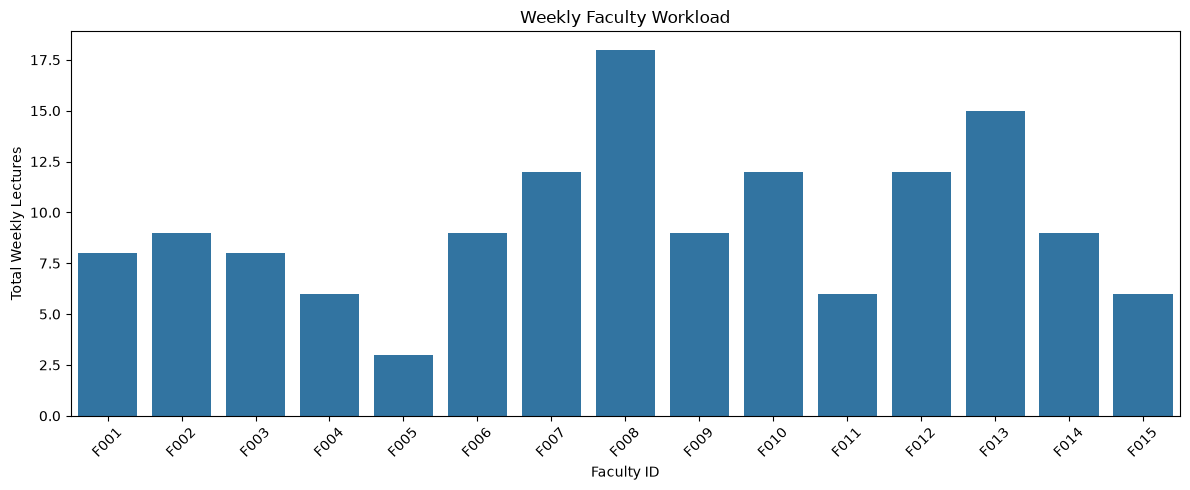

In [13]:

# =====================================================
# FACULTY WORKLOAD ANALYSIS
# =====================================================

faculty_workload = (
    batch_subjects
    .groupby("faculty_id")["lectures_per_week"]
    .sum()
    .reset_index()
)

faculty_workload.columns = [
    "faculty_id",
    "total_weekly_lectures"
]

print(faculty_workload)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=faculty_workload,
    x="faculty_id",
    y="total_weekly_lectures"
)

plt.title("Weekly Faculty Workload")
plt.xlabel("Faculty ID")
plt.ylabel("Total Weekly Lectures")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


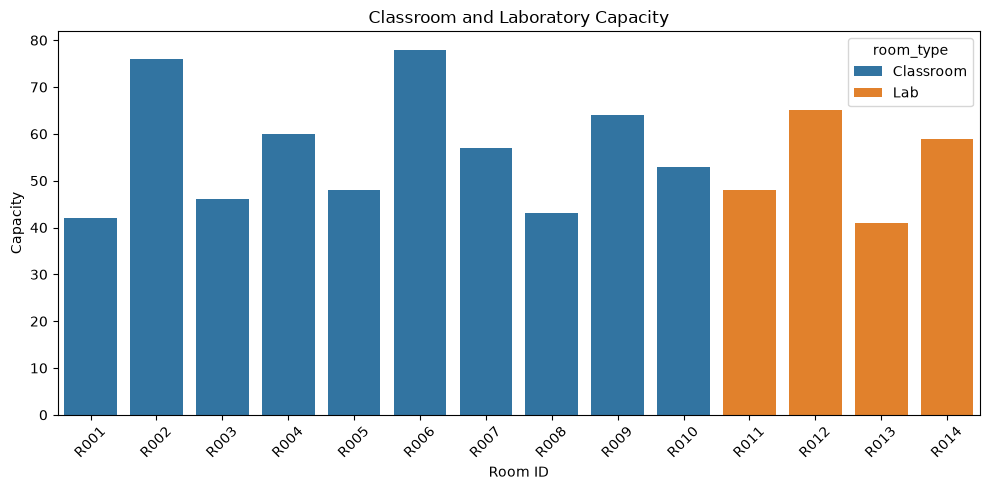

In [14]:

# =====================================================
# CLASSROOM CAPACITY ANALYSIS
# =====================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=classrooms,
    x="room_id",
    y="capacity",
    hue="room_type"
)

plt.title("Classroom and Laboratory Capacity")
plt.xlabel("Room ID")
plt.ylabel("Capacity")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


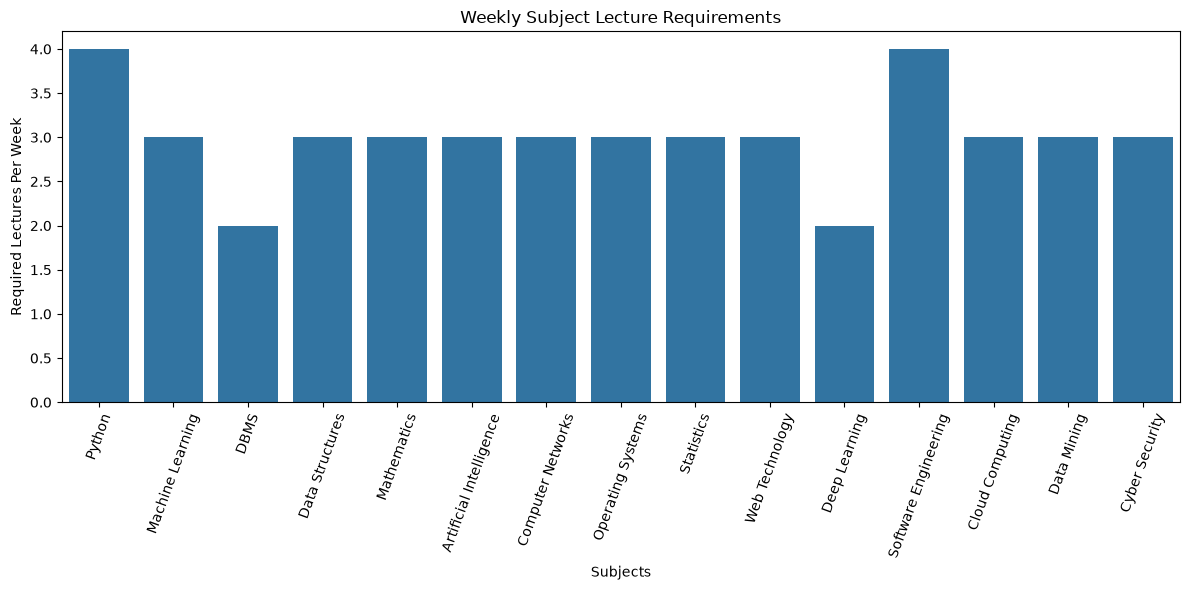

In [15]:

# =====================================================
# SUBJECT DEMAND ANALYSIS
# =====================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=subjects,
    x="subject_name",
    y="required_lectures_per_week"
)

plt.title("Weekly Subject Lecture Requirements")
plt.xlabel("Subjects")
plt.ylabel("Required Lectures Per Week")

plt.xticks(rotation=70)
plt.tight_layout()
plt.show()


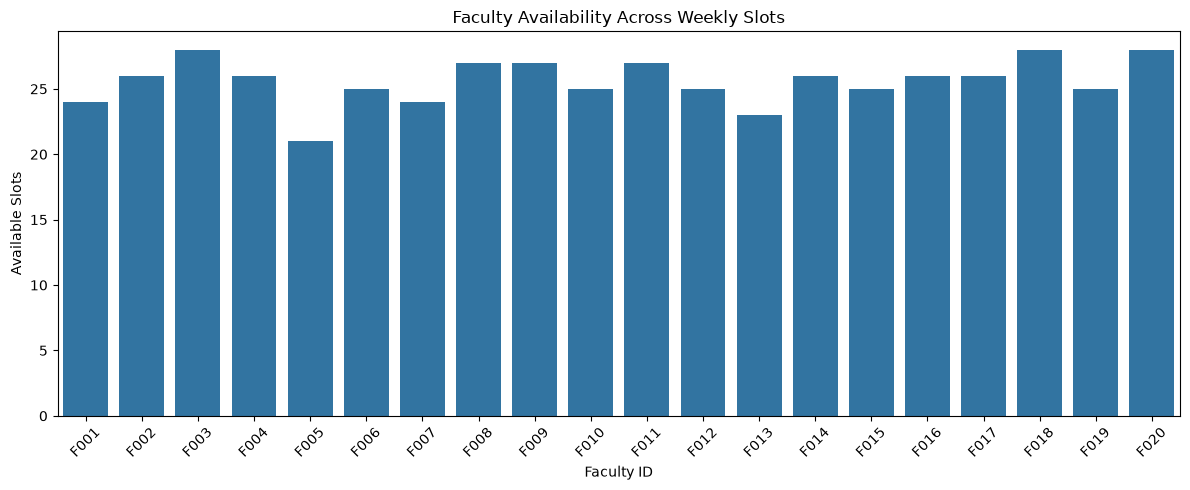

In [16]:

# =====================================================
# FACULTY AVAILABILITY ANALYSIS
# =====================================================

availability_summary = (
    faculty_availability
    .groupby("faculty_id")["available"]
    .sum()
    .reset_index()
)

availability_summary.columns = [
    "faculty_id",
    "available_slots"
]

plt.figure(figsize=(12, 5))

sns.barplot(
    data=availability_summary,
    x="faculty_id",
    y="available_slots"
)

plt.title("Faculty Availability Across Weekly Slots")
plt.xlabel("Faculty ID")
plt.ylabel("Available Slots")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [17]:

# =====================================================
# DATA RELATIONSHIP VALIDATION
# =====================================================

print("Invalid Faculty References:",
      (~batch_subjects["faculty_id"].isin(
          faculty["faculty_id"]
      )).sum())

print("Invalid Subject References:",
      (~batch_subjects["subject_id"].isin(
          subjects["subject_id"]
      )).sum())

print("Invalid Batch References:",
      (~batch_subjects["batch_id"].isin(
          batches["batch_id"]
      )).sum())

print("Invalid Time Slot References:",
      (~faculty_availability["slot_id"].isin(
          time_slots["slot_id"]
      )).sum())

print("\nValidation Completed!")


Invalid Faculty References: 0
Invalid Subject References: 0
Invalid Batch References: 0
Invalid Time Slot References: 0

Validation Completed!
